In [10]:
import os
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D
from tensorflow.keras.layers import Dropout, Flatten, Dense


In [11]:
BASE_DIR = r"C:\Users\ASUS\Desktop\Phone_screen CNN"

TRAIN_DIR = os.path.join(BASE_DIR, "aug", "train")
VAL_DIR = os.path.join(BASE_DIR, "validation")

In [12]:
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(128, 128),
    batch_size=8,
    class_mode="binary"
)

val_data = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(128, 128),
    batch_size=8,
    class_mode="binary"
)

Found 660 images belonging to 2 classes.
Found 15 images belonging to 2 classes.


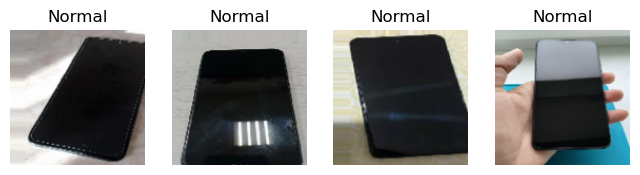

In [13]:
images, labels = next(train_data)

plt.figure(figsize=(8, 4))

for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i])
    plt.title("Cracked" if labels[i] == 1 else "Normal")
    plt.axis("off")

plt.show()

In [36]:
model = Sequential([
    Input(shape=(128,128,3)),

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Dropout(0.25),
    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

In [37]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [34]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │    10,616,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,636,481 (40.57 MB)

 Trainable params: 10,636,481 (40.57 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20
)

Epoch 1/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 13s 126ms/step - accuracy: 0.8712 - loss: 0.3438 - val_accuracy: 1.0000 - val_loss: 0.0158
Epoch 2/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - accuracy: 0.9667 - loss: 0.0983 - val_accuracy: 1.0000 - val_loss: 0.0114
Epoch 3/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 9s 112ms/step - accuracy: 0.9864 - loss: 0.0472 - val_accuracy: 1.0000 - val_loss: 9.0661e-04
Epoch 4/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - accuracy: 0.9879 - loss: 0.0313 - val_accuracy: 0.9333 - val_loss: 0.1451
Epoch 5/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 9s 113ms/step - accuracy: 0.9970 - loss: 0.0180 - val_accuracy: 1.0000 - val_loss: 4.9086e-06
Epoch 6/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 9s 113ms/step - accuracy: 0.9955 - loss: 0.0093 - val_accuracy: 1.0000 - val_loss: 4.1226e-04
Epoch 7/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 9s 113ms/step - accuracy: 0.9985 - loss: 0.0041 - val_accuracy: 1.0000 - val_loss: 3.7811e-06
Epoch 8/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 9s 112ms/step - accuracy: 0.9894 - loss: 0.0275 -

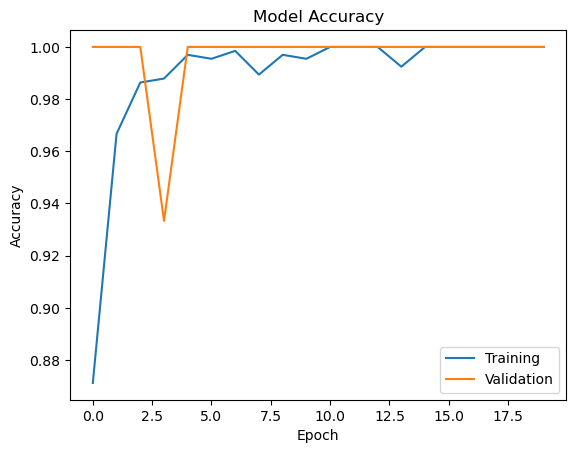

In [38]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Training", "Validation"])

plt.show()

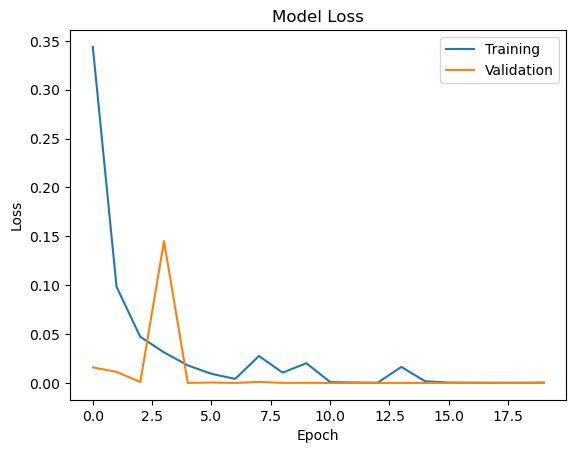

In [39]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Training", "Validation"])

plt.show()


In [40]:
model.save(os.path.join(BASE_DIR, "phone_screen_model.keras"))

print("Model saved successfully!")

Model saved successfully!


In [41]:
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 280ms/step - accuracy: 0.4000 - loss: 0.6962
Validation Loss: 0.6961928009986877
Validation Accuracy: 40.00000059604645 %
